# Sales Data Analysis Project

## Objective
In this project, I will use Python to look at the sales data and find some useful information about sales, products, branches, customers, and payment methods.

## Questions
1. Which product line has the most sales?
2. Which branch has the most sales?
3. How do sales change by month?
4. Which payment method is used the most?
5. Do members and normal customers have different sales?
6. Is quantity related to total sales?
7. Which product line has the best rating?
8. Which day has the most sales?


## 1. Import Libraries

I used pandas for working with the data and matplotlib and seaborn for the charts.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


## 2. Load the Dataset




In [ ]:
from pathlib import Path
from google.colab import files

file_path = Path("/content/sales_dataset.xlsx")

if not file_path.exists():
    print("Please upload sales_dataset.xlsx")
    uploaded = files.upload()
    uploaded_name = next(iter(uploaded))
    file_path = Path("/content") / uploaded_name

df = pd.read_excel(file_path)

print(f"Dataset loaded successfully: {file_path.name}")


Please upload sales_dataset.xlsx


Saving sales_dataset.xlsx to sales_dataset.xlsx
Dataset loaded successfully: sales_dataset.xlsx


## 3. Explore the Dataset

First, I checked the first and last rows, the size of the dataset, the column names, and the data types.


In [ ]:
display(df.head())
display(df.tail())

print("Shape:", df.shape)

print("Column names:")
print(df.columns.tolist())

print("Data types:")
df.info()


,ID,Invoice ID,Branch,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,...,Payment,COGS,Gross Margin Percentage,Gross Income,customer type 2,quantity2,payment2,total2,Branch2,Rating
0,2873,750-67-8428,A,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,...,Ewallet,522.83,4.761905,26.1415,Member,7,Ewallet,548.9715,A,9.1
1,1629,226-31-3081,C,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,...,Cash,76.40,4.761905,3.8200,Normal,5,Cash,80.2200,C,9.6
2,1239,631-41-3108,A,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,...,Credit card,324.31,4.761905,16.2155,Normal,7,Credit card,340.5255,A,7.4
3,1191,NaN,A,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,...,Ewallet,465.76,4.761905,23.2880,Member,8,Ewallet,489.0480,A,8.4
4,1116,373-73-7910,A,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,...,Ewallet,604.17,4.761905,30.2085,Normal,7,Ewallet,634.3785,A,5.3


,ID,Invoice ID,Branch,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,...,Payment,COGS,Gross Margin Percentage,Gross Income,customer type 2,quantity2,payment2,total2,Branch2,Rating
995,1919,233-67-5758,C,Normal,Male,Health and beauty,40.35,1,2.0175,42.3675,...,Ewallet,40.35,4.761905,2.0175,Normal,1,Ewallet,42.3675,C,6.2
996,1326,303-96-2227,B,Normal,Female,Home and lifestyle,97.38,10,48.6900,1022.4900,...,Ewallet,973.80,4.761905,48.6900,Normal,10,Ewallet,1022.4900,B,4.4
997,2901,727-02-1313,A,Member,Male,Food and beverages,31.84,1,1.5920,33.4320,...,Cash,31.84,4.761905,1.5920,Member,1,Cash,33.4320,A,7.7
998,2236,347-56-2442,A,Normal,Male,Home and lifestyle,65.82,1,3.2910,69.1110,...,Cash,65.82,4.761905,3.2910,Normal,1,Cash,69.1110,A,4.1
999,2678,849-09-3807,A,Member,Female,Fashion accessories,88.34,7,30.9190,649.2990,...,Cash,618.38,4.761905,30.9190,Member,7,Cash,649.2990,A,6.6


Shape: (1000, 22)
Column names:
['ID', 'Invoice ID', 'Branch', 'Customer type', 'Gender', 'Product line', 'Unit price', 'Quantity', 'Tax 5%', 'Total', 'Date', 'Time', 'Payment', 'COGS', 'Gross Margin Percentage', 'Gross Income', 'customer type 2', 'quantity2', 'payment2', 'total2', 'Branch2', 'Rating']
Data types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 22 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   ID                       1000 non-null   int64         
 1   Invoice ID               999 non-null    object        
 2   Branch                   999 non-null    object        
 3   Customer type            1000 non-null   object        
 4   Gender                   1000 non-null   object        
 5   Product line             1000 non-null   object        
 6   Unit price               1000 non-null   float64       
 7   Quantity                

In [ ]:
display(df.describe(include="all").T)


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
ID,1000.0,NaN,NaN,NaN,2119.063,1001.0,1577.5,2104.0,2691.75,3220.0,646.025267
Invoice ID,999,999,849-09-3807,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Branch,999,3,A,340,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer type,1000,3,Member,500,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,1000,2,Female,501,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product line,1000,6,Fashion accessories,178,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Unit price,1000.0,NaN,NaN,NaN,55.67213,10.08,32.875,55.23,77.935,99.96,26.494628
Quantity,1000.0,11.0,10.0,118.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tax 5%,1000.0,NaN,NaN,NaN,15.379369,0.5085,5.924875,12.088,22.44525,49.65,11.708825
Total,999.0,NaN,NaN,NaN,322.680429,10.6785,123.78975,253.68,471.009,1042.65,245.841652


## 4. Check Missing Values and Duplicates

I checked the dataset for missing values, duplicates, and some values that look incorrect.


In [ ]:
print("Missing values:")
print(df.isna().sum())

print("Duplicates:", df.duplicated().sum())


Missing values:
ID                         0
Invoice ID                 1
Branch                     1
Customer type              0
Gender                     0
Product line               0
Unit price                 0
Quantity                   0
Tax 5%                     0
Total                      1
Date                       0
Time                       0
Payment                    0
COGS                       0
Gross Margin Percentage    0
Gross Income               0
customer type 2            0
quantity2                  0
payment2                   0
total2                     0
Branch2                    0
Rating                     0
dtype: int64
Duplicates: 0


In [ ]:
print("Branch:")
print(df["Branch"].value_counts(dropna=False))

print("\nCustomer type:")
print(df["Customer type"].value_counts(dropna=False))

print("\nPayment:")
print(df["Payment"].value_counts(dropna=False))

print("\nQuantity:")
print(df["Quantity"].value_counts(dropna=False))


Branch:
Branch
A      340
B      332
C      327
NaN      1
Name: count, dtype: int64

Customer type:
Customer type
Member    500
Normal    499
Meber       1
Name: count, dtype: int64

Payment:
Payment
Ewallet        345
Cash           343
Credit card    311
Ca-sh            1
Name: count, dtype: int64

Quantity:
Quantity
10       118
1        112
4        109
7        102
5        102
6         98
9         92
2         91
3         90
8         85
Ã¨Â§0      1
Name: count, dtype: int64


## 5. Clean the Data

I fixed the incorrect values and filled in some missing values using the extra columns in the dataset. I also removed duplicate rows.


In [ ]:
clean = df.copy()

clean["Branch"] = clean["Branch"].fillna(clean["Branch2"])
clean["Customer type"] = clean["Customer type"].replace("Meber", "Member")
clean["Payment"] = clean["Payment"].replace("Ca-sh", "Cash")

clean["Quantity"] = pd.to_numeric(clean["Quantity"], errors="coerce")
clean["Quantity"] = clean["Quantity"].fillna(clean["quantity2"])

clean["Total"] = clean["Total"].fillna(clean["total2"])
clean["Invoice ID"] = clean["Invoice ID"].fillna("Unknown")

clean = clean.drop_duplicates()

clean["Month"] = clean["Date"].dt.to_period("M").astype(str)
clean["Day of Week"] = clean["Date"].dt.day_name()
clean["Hour"] = clean["Time"].apply(lambda x: x.hour)

clean = clean.drop(columns=["customer type 2", "quantity2", "payment2", "total2", "Branch2"])

print("Rows after cleaning:", len(clean))
display(clean.head())


Rows after cleaning: 1000


,ID,Invoice ID,Branch,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,COGS,Gross Margin Percentage,Gross Income,Rating,Month,Day of Week,Hour
0,2873,750-67-8428,A,Member,Female,Health and beauty,74.69,7.0,26.1415,548.9715,2019-01-05,13:08:00,Ewallet,522.83,4.761905,26.1415,9.1,2019-01,Saturday,13
1,1629,226-31-3081,C,Normal,Female,Electronic accessories,15.28,5.0,3.8200,80.2200,2019-03-08,10:29:00,Cash,76.40,4.761905,3.8200,9.6,2019-03,Friday,10
2,1239,631-41-3108,A,Normal,Male,Home and lifestyle,46.33,7.0,16.2155,340.5255,2019-03-03,13:23:00,Credit card,324.31,4.761905,16.2155,7.4,2019-03,Sunday,13
3,1191,Unknown,A,Member,Male,Health and beauty,58.22,8.0,23.2880,489.0480,2019-01-27,20:33:00,Ewallet,465.76,4.761905,23.2880,8.4,2019-01,Sunday,20
4,1116,373-73-7910,A,Normal,Male,Sports and travel,86.31,7.0,30.2085,634.3785,2019-02-08,10:37:00,Ewallet,604.17,4.761905,30.2085,5.3,2019-02,Friday,10


In [ ]:
print("Missing values after cleaning:")
print(clean.isna().sum())

print("\nDuplicates after cleaning:", clean.duplicated().sum())


Missing values after cleaning:
ID                         0
Invoice ID                 0
Branch                     0
Customer type              0
Gender                     0
Product line               0
Unit price                 0
Quantity                   0
Tax 5%                     0
Total                      0
Date                       0
Time                       0
Payment                    0
COGS                       0
Gross Margin Percentage    0
Gross Income               0
Rating                     0
Month                      0
Day of Week                0
Hour                       0
dtype: int64

Duplicates after cleaning: 0


## 6. Summary of the Data

Here is a quick summary of the cleaned dataset.


In [ ]:
print("Number of transactions:", len(clean))
print("Total sales:", clean["Total"].sum())
print("Average transaction:", clean["Total"].mean())
print("Median transaction:", clean["Total"].median())
print("Total gross income:", clean["Gross Income"].sum())
print("Average rating:", clean["Rating"].mean())
print("Total quantity sold:", clean["Quantity"].sum())


Number of transactions: 1000
Total sales: 322966.749
Average transaction: 322.966749
Median transaction: 253.848
Total gross income: 15379.368999999999
Average rating: 6.9727
Total quantity sold: 5510.0


# 7. Data Analysis

## Question 1: Which product lines have the most sales?


Product line
Food and beverages        56144.8440
Sports and travel         55122.8265
Electronic accessories    54337.5315
Fashion accessories       54305.8950
Home and lifestyle        53861.9130
Health and beauty         49193.7390
Name: Total, dtype: float64


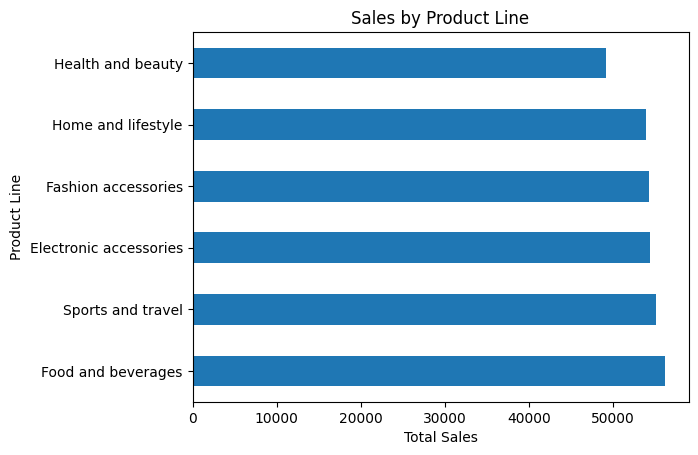

In [ ]:
product_sales = clean.groupby("Product line")["Total"].sum().sort_values(ascending=False)

print(product_sales)

product_sales.plot(kind="barh")
plt.title("Sales by Product Line")
plt.xlabel("Total Sales")
plt.ylabel("Product Line")
plt.show()


**Finding:** Food and beverages has the highest sales. Health and beauty has the lowest.


## Question 2: Which branch has the most sales?


Branch
C    109988.8650
B    106777.5135
A    106200.3705
Name: Total, dtype: float64


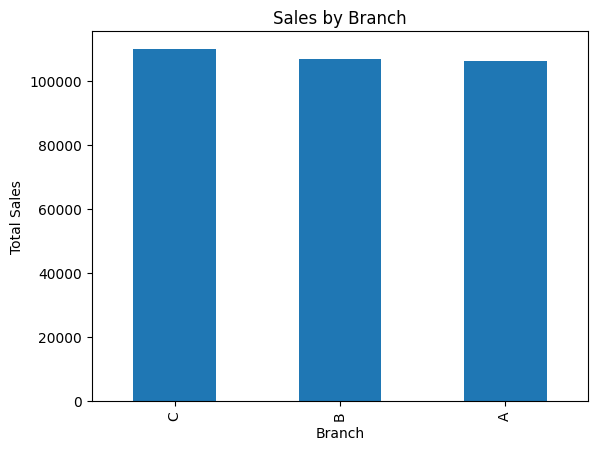

In [ ]:
branch_sales = clean.groupby("Branch")["Total"].sum().sort_values(ascending=False)

print(branch_sales)

branch_sales.plot(kind="bar")
plt.title("Sales by Branch")
plt.xlabel("Branch")
plt.ylabel("Total Sales")
plt.show()


**Finding:** Branch C has the highest sales, while Branch A has the lowest.


## Question 3: How do sales change by month?


Month
2019-01    116291.868
2019-02     97219.374
2019-03    109455.507
Name: Total, dtype: float64


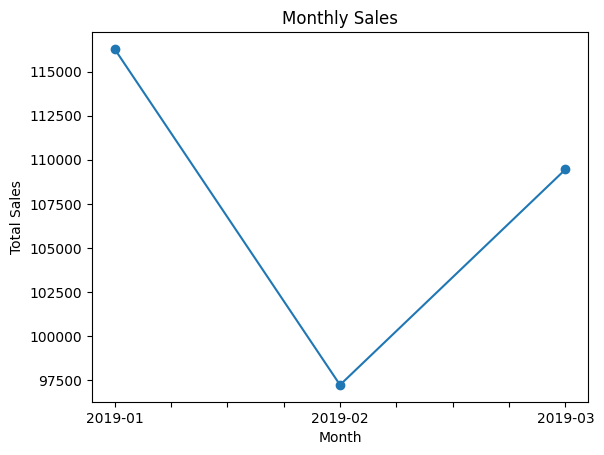

In [ ]:
monthly_sales = clean.groupby("Month")["Total"].sum()

print(monthly_sales)

monthly_sales.plot(kind="line", marker="o")
plt.title("Monthly Sales")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.show()


**Finding:** January has the highest sales. Sales go down in February and then increase again in March.


## Question 4: Which payment method is used the most?


             count         sum
Payment                       
Cash           344  112206.570
Credit card    311  100767.072
Ewallet        345  109993.107


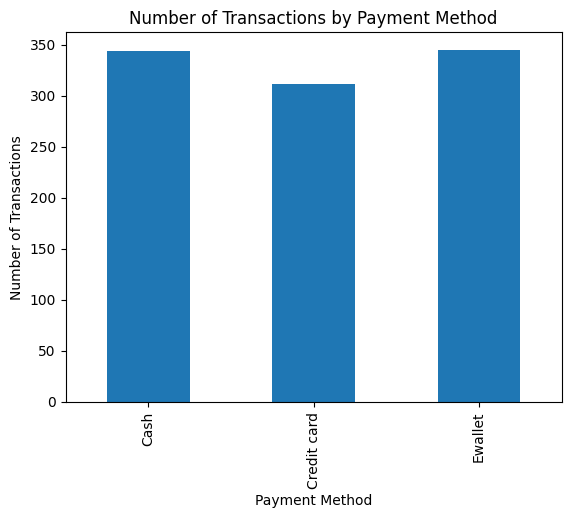

In [ ]:
payment_sales = clean.groupby("Payment")["Total"].agg(["count", "sum"])

print(payment_sales)

payment_sales["count"].plot(kind="bar")
plt.title("Number of Transactions by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Transactions")
plt.show()


**Finding:** Cash is the most common payment method and also has the highest total sales.


## Question 5: Do members and normal customers have different sales?


               count         sum        mean
Customer type                               
Member           501  164223.444  327.791305
Normal           499  158743.305  318.122856


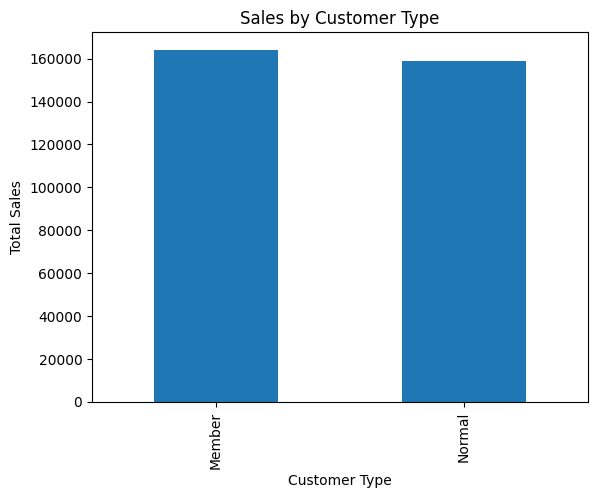

In [ ]:
customer_sales = clean.groupby("Customer type")["Total"].agg(["count", "sum", "mean"])

print(customer_sales)

customer_sales["sum"].plot(kind="bar")
plt.title("Sales by Customer Type")
plt.xlabel("Customer Type")
plt.ylabel("Total Sales")
plt.show()


**Finding:** Members have slightly more sales than normal customers.


## Question 6: Is quantity related to total sales?


              Quantity  Unit price     Total  Gross Income    Rating
Quantity      1.000000    0.010778  0.705510      0.705510 -0.015815
Unit price    0.010778    1.000000  0.633962      0.633962 -0.008778
Total         0.705510    0.633962  1.000000      1.000000 -0.036442
Gross Income  0.705510    0.633962  1.000000      1.000000 -0.036442
Rating       -0.015815   -0.008778 -0.036442     -0.036442  1.000000


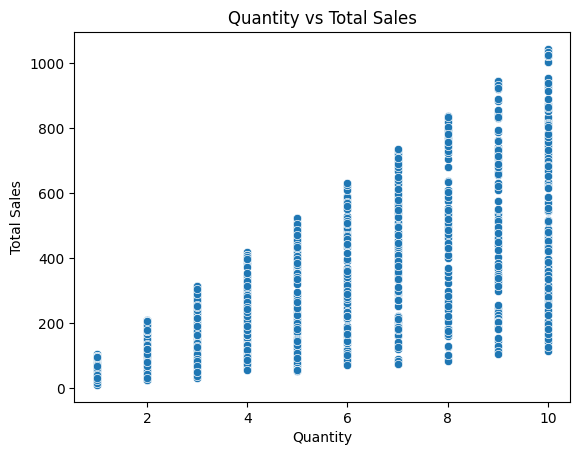

In [ ]:
print(clean[["Quantity", "Unit price", "Total", "Gross Income", "Rating"]].corr())

sns.scatterplot(data=clean, x="Quantity", y="Total")
plt.title("Quantity vs Total Sales")
plt.xlabel("Quantity")
plt.ylabel("Total Sales")
plt.show()


**Finding:** Quantity and total sales have a positive relationship. The correlation is about 0.71.


## Question 7: Which product lines have the best ratings?


Product line
Food and beverages        7.113218
Fashion accessories       7.029213
Health and beauty         7.003289
Electronic accessories    6.924706
Sports and travel         6.916265
Home and lifestyle        6.837500
Name: Rating, dtype: float64


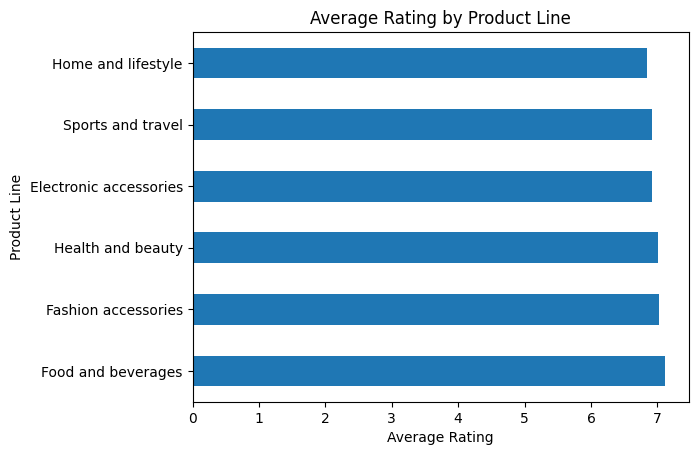

In [ ]:
rating = clean.groupby("Product line")["Rating"].mean().sort_values(ascending=False)

print(rating)

rating.plot(kind="barh")
plt.title("Average Rating by Product Line")
plt.xlabel("Average Rating")
plt.ylabel("Product Line")
plt.show()


**Finding:** Food and beverages has the highest average rating. Home and lifestyle has the lowest.


## Question 8: Which day of the week has the most sales?


Day of Week
Monday       37899.0780
Tuesday      51482.2455
Wednesday    43731.1350
Thursday     45349.2480
Friday       43926.3405
Saturday     56120.8095
Sunday       44457.8925
Name: Total, dtype: float64


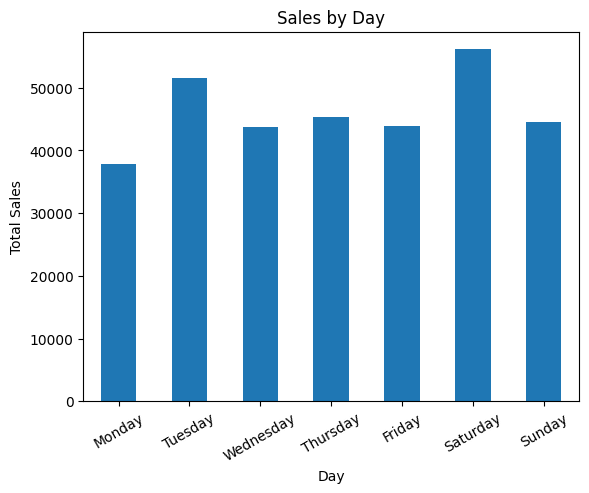

In [ ]:
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

day_sales = clean.groupby("Day of Week")["Total"].sum().reindex(days)

print(day_sales)

day_sales.plot(kind="bar")
plt.title("Sales by Day")
plt.xlabel("Day")
plt.ylabel("Total Sales")
plt.xticks(rotation=30)
plt.show()


**Finding:** Saturday has the highest total sales and Monday has the lowest.


# 8. Extra Analysis

I also checked how the product lines perform in each branch.


Branch,A,B,C
Product line,,,
Electronic accessories,18317.1135,17051.4435,18968.9745
Fashion accessories,16332.5085,16413.3165,21560.0700
Food and beverages,17163.1005,15214.8885,23766.8550
Health and beauty,12597.7530,20560.5015,16035.4845
Home and lifestyle,22417.1955,17549.1645,13895.5530
Sports and travel,19372.6995,19988.1990,15761.9280


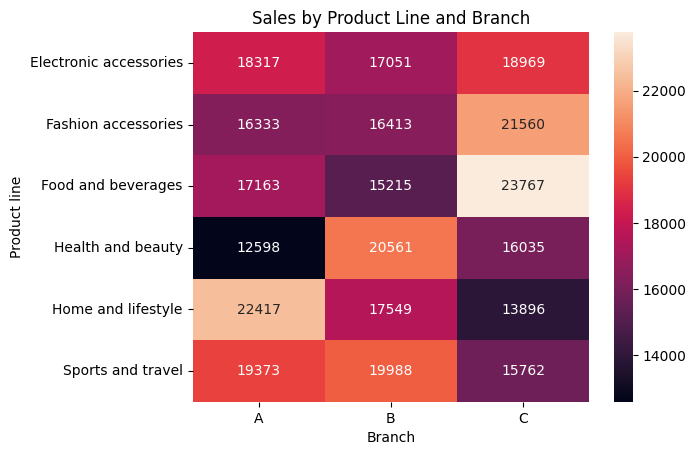

In [ ]:
branch_product = pd.pivot_table(
    clean,
    values="Total",
    index="Product line",
    columns="Branch",
    aggfunc="sum"
)

display(branch_product)

sns.heatmap(branch_product, annot=True, fmt=".0f")
plt.title("Sales by Product Line and Branch")
plt.show()


The main results I found are:

- There are 1,000 transactions.
- Food and beverages has the highest sales.
- Branch C has the highest sales.
- January has the highest monthly sales.
- Cash is the most common payment method.
- Members have slightly higher total sales than normal customers.
- Saturday has the highest sales.
